<a href="https://colab.research.google.com/github/Houcineaberhache/nanoGPT-Scaling-Laws/blob/feature%2Fevaluation/notebooks/evaluation_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Evaluation Notebook — Evaluation Engineer

 > 🟡 These cells ran successfully on the 6 trained checkpoints (E1–E6). Review them, change what you want, and make them yours.
> The reusable logic should end up in `src/evaluation/evaluate.py` and `src/evaluation/generate.py`.

## Evaluation Engineer's tasks (from the project plan)
- [x] Compute Loss and Perplexity
- [x] Compare the 6 experiments
- [x] Generate learning curves
- [x] Analyse the generated texts
- [x] Compare against the **bigram baseline**
- [x] Study scaling laws

## 💡 Things worth checking (suggestions, not bugs)
1. **Test-loss sampling:** the evaluation draws 200 random windows from a 111 k-token test set (≈ 14× the test set, with overlaps). An exhaustive, non-overlapping pass over `test.bin` would be a cleaner "same test set for all models".
2. **`BLOCK_SIZE = 256` is hard-coded** — safer to read it from the checkpoint config.
3. **Overfitting story:** E4 and E5 (Medium, little data) reach their best validation loss at iteration 2250 and then overfit (E4 final val loss 2.57 vs best 1.96). `best.pt` is used for the test, which is correct — but explain it in the report.
4. **Fixed 5000 iterations for every run** means the 25 % runs see their data ~4× more often (epochs) than the 100 % runs. Worth stating as a limit of the experimental design.
5. Perplexity here is **per character** (vocab = 65) — not comparable to word-level perplexities.

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content

import os
if not os.path.exists("nanoGPT-Scaling-Laws"):
    !git clone https://github.com/Houcineaberhache/nanoGPT-Scaling-Laws.git

%cd /content/nanoGPT-Scaling-Laws
!git checkout main
!git pull origin main
!pip install -q -r requirements.txt

/content
/content/nanoGPT-Scaling-Laws
Already on 'main'
Your branch is up to date with 'origin/main'.
From https://github.com/Houcineaberhache/nanoGPT-Scaling-Laws
 * branch            main       -> FETCH_HEAD
Already up to date.


## 2. Test-set Loss & Perplexity  *(task: Loss and Perplexity)*

In [ ]:
import os
import math
import torch
import numpy as np
import pandas as pd
import pickle

from src.models.model import GPT, GPTConfig

# --------------------------------------------------
# 1. Paths and evaluation settings
# --------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/nanoGPT-Scaling-Laws"
TEST_PATH = "data/processed/test.bin"

BATCH_SIZE = 32
EVAL_BATCHES = 200
BLOCK_SIZE = 256
SEED = 1234

device = "cuda" if torch.cuda.is_available() else "cpu"

# Load test data
test_data = torch.from_numpy(
    np.fromfile(TEST_PATH, dtype=np.uint16).astype(np.int64)
)

# Load vocabulary metadata
with open("data/processed/meta.pkl", "rb") as f:
    meta = pickle.load(f)

vocab_size = meta["vocab_size"]

print("Device:", device)
print("Test tokens:", len(test_data))
print("Vocabulary size:", vocab_size)

# --------------------------------------------------
# 2. Evaluation function
# --------------------------------------------------

@torch.no_grad()
def evaluate_checkpoint(exp_name, model_type, data_percentage):

    checkpoint_path = os.path.join(
        BASE_DIR, "results", exp_name, "best.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    # Reconstruct model from saved configuration
    config = GPTConfig(**checkpoint["config"])
    model = GPT(config).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    # Fixed random batches for reproducibility
    generator = torch.Generator(device="cpu")
    generator.manual_seed(SEED)

    losses = []

    for _ in range(EVAL_BATCHES):

        ix = torch.randint(
            len(test_data) - BLOCK_SIZE - 1,
            (BATCH_SIZE,),
            generator=generator
        )

        x = torch.stack([
            test_data[i:i + BLOCK_SIZE] for i in ix
        ]).to(device)

        y = torch.stack([
            test_data[i + 1:i + BLOCK_SIZE + 1] for i in ix
        ]).to(device)

        _, loss = model(x, y)
        losses.append(loss.item())

    test_loss = float(np.mean(losses))
    test_perplexity = math.exp(test_loss)

    result = {
        "Experiment": exp_name,
        "Model": model_type,
        "Data": data_percentage,
        "Parameters": model.get_num_params(),
        "Best Val Loss": checkpoint["val_loss"],
        "Test Loss": test_loss,
        "Test Perplexity": test_perplexity
    }

    print(
        f"{exp_name} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test PPL: {test_perplexity:.2f}"
    )

    del model, checkpoint
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# --------------------------------------------------
# 3. Evaluate E1 to E6
# --------------------------------------------------

experiments = [
    ("E1", "Small", "25%"),
    ("E2", "Small", "50%"),
    ("E3", "Small", "100%"),
    ("E4", "Medium", "25%"),
    ("E5", "Medium", "50%"),
    ("E6", "Medium", "100%"),
]

results = []

for exp_name, model_type, percentage in experiments:
    result = evaluate_checkpoint(
        exp_name,
        model_type,
        percentage
    )
    results.append(result)


# --------------------------------------------------
# 4. Display and save results
# --------------------------------------------------

test_results = pd.DataFrame(results)

print("\nFINAL TEST SET RESULTS")
display(test_results.round(4))

output_path = os.path.join(
    BASE_DIR, "results", "test_evaluation.csv"
)

test_results.to_csv(output_path, index=False)

print("\nResults saved to:", output_path)

Device: cuda
Test tokens: 111540
Vocabulary size: 65
E1 | Test Loss: 2.1067 | Test PPL: 8.22
E2 | Test Loss: 2.0416 | Test PPL: 7.70
E3 | Test Loss: 1.8887 | Test PPL: 6.61
E4 | Test Loss: 2.0911 | Test PPL: 8.09
E5 | Test Loss: 1.9612 | Test PPL: 7.11
E6 | Test Loss: 1.7430 | Test PPL: 5.71

FINAL TEST SET RESULTS


,Experiment,Model,Data,Parameters,Best Val Loss,Test Loss,Test Perplexity
0,E1,Small,25%,828672,2.0041,2.1067,8.2213
1,E2,Small,50%,828672,1.9314,2.0416,7.7031
2,E3,Small,100%,828672,1.6743,1.8887,6.6105
3,E4,Medium,25%,4804096,1.9634,2.0911,8.0939
4,E5,Medium,50%,4804096,1.8146,1.9612,7.1080
5,E6,Medium,100%,4804096,1.4648,1.7430,5.7144



Results saved to: /content/drive/MyDrive/nanoGPT-Scaling-Laws/results/test_evaluation.csv


## Building and evaluating the Bigram baseline :

In [ ]:
import os
import math
import torch
import numpy as np
import pandas as pd

from src.models.baseline import BigramLanguageModel

# ------------------------------------------
# 1. Load the FULL training dataset (100%)
# ------------------------------------------

TRAIN_PATH = "/content/nanoGPT-Scaling-Laws/data/processed/train_100.bin"

train_data = torch.from_numpy(
    np.fromfile(TRAIN_PATH, dtype=np.uint16).astype(np.int64)
)

print("Training tokens:", len(train_data))
print("Training dataset loaded successfully!")

# ------------------------------------------
# 2. Build Bigram from training data
# ------------------------------------------

bigram_model = BigramLanguageModel.from_counts(
    train_ids=train_data,
    vocab_size=vocab_size,
    block_size=BLOCK_SIZE
).to(device)

bigram_model.eval()

print("Bigram parameters:", bigram_model.get_num_params())

# ------------------------------------------
# 3. Evaluate on the SAME test batches
# ------------------------------------------

generator = torch.Generator(device="cpu")
generator.manual_seed(SEED)

bigram_losses = []

with torch.no_grad():

    for _ in range(EVAL_BATCHES):

        ix = torch.randint(
            len(test_data) - BLOCK_SIZE - 1,
            (BATCH_SIZE,),
            generator=generator
        )

        x = torch.stack([
            test_data[i:i + BLOCK_SIZE] for i in ix
        ]).to(device)

        y = torch.stack([
            test_data[i + 1:i + BLOCK_SIZE + 1] for i in ix
        ]).to(device)

        logits, loss = bigram_model(x, y)

        bigram_losses.append(loss.item())

# Calculate metrics
bigram_test_loss = float(np.mean(bigram_losses))
bigram_test_perplexity = math.exp(bigram_test_loss)

print("\n========== BIGRAM RESULTS ==========")
print(f"Test Loss: {bigram_test_loss:.4f}")
print(f"Test Perplexity: {bigram_test_perplexity:.4f}")

# ------------------------------------------
# 4. Add Bigram to test_evaluation.csv
# ------------------------------------------

bigram_result = {
    "Experiment": "Bigram",
    "Model": "Baseline",
    "Data": "100%",
    "Parameters": bigram_model.get_num_params(),
    "Best Val Loss": np.nan,
    "Test Loss": bigram_test_loss,
    "Test Perplexity": bigram_test_perplexity
}

results_path = os.path.join(
    BASE_DIR, "results", "test_evaluation.csv"
)

test_results = pd.read_csv(results_path)

# Avoid duplicate rows if cell is executed again
test_results = test_results[
    test_results["Experiment"] != "Bigram"
]

test_results = pd.concat(
    [test_results, pd.DataFrame([bigram_result])],
    ignore_index=True
)

test_results.to_csv(results_path, index=False)

print("\nUPDATED TEST EVALUATION")
display(test_results.round(4))

# Cleanup
del bigram_model, train_data

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Training tokens: 892315
Training dataset loaded successfully!
Bigram parameters: 4225

========== BIGRAM RESULTS ==========
Test Loss: 2.5035
Test Perplexity: 12.2248

UPDATED TEST EVALUATION


,Experiment,Model,Data,Parameters,Best Val Loss,Test Loss,Test Perplexity
0,E1,Small,25%,828672,2.0041,2.1067,8.2213
1,E2,Small,50%,828672,1.9314,2.0416,7.7031
2,E3,Small,100%,828672,1.6743,1.8887,6.6105
3,E4,Medium,25%,4804096,1.9634,2.0911,8.0939
4,E5,Medium,50%,4804096,1.8146,1.9612,7.1080
5,E6,Medium,100%,4804096,1.4648,1.7430,5.7144
6,Bigram,Baseline,100%,4225,NaN,2.5035,12.2248


## 3. Learning curves  *(task: learning curves)*

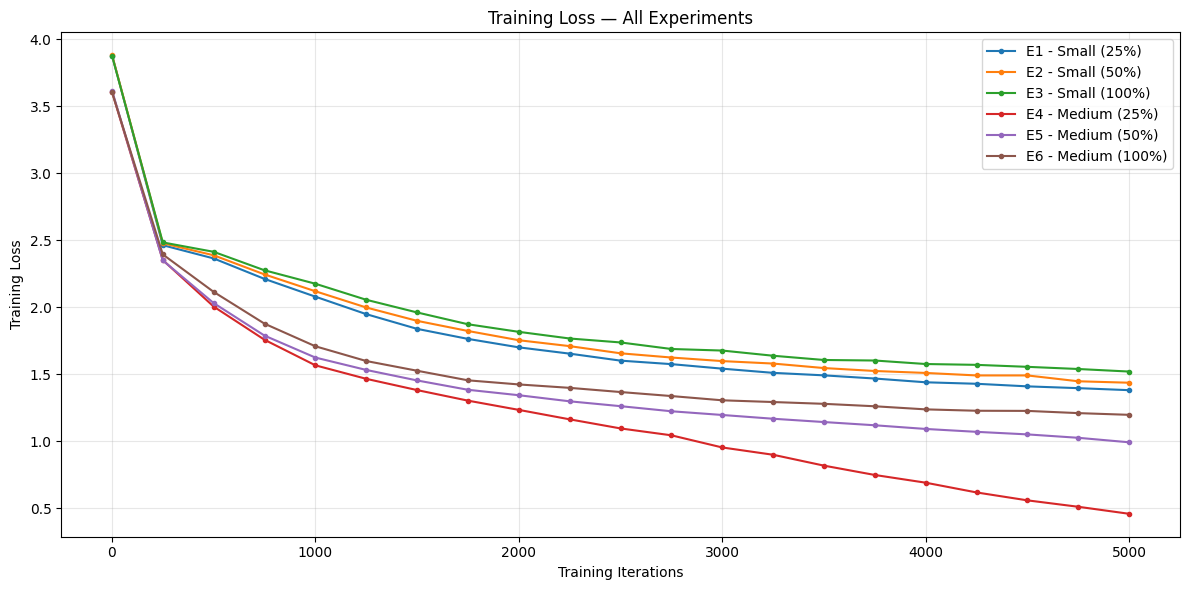

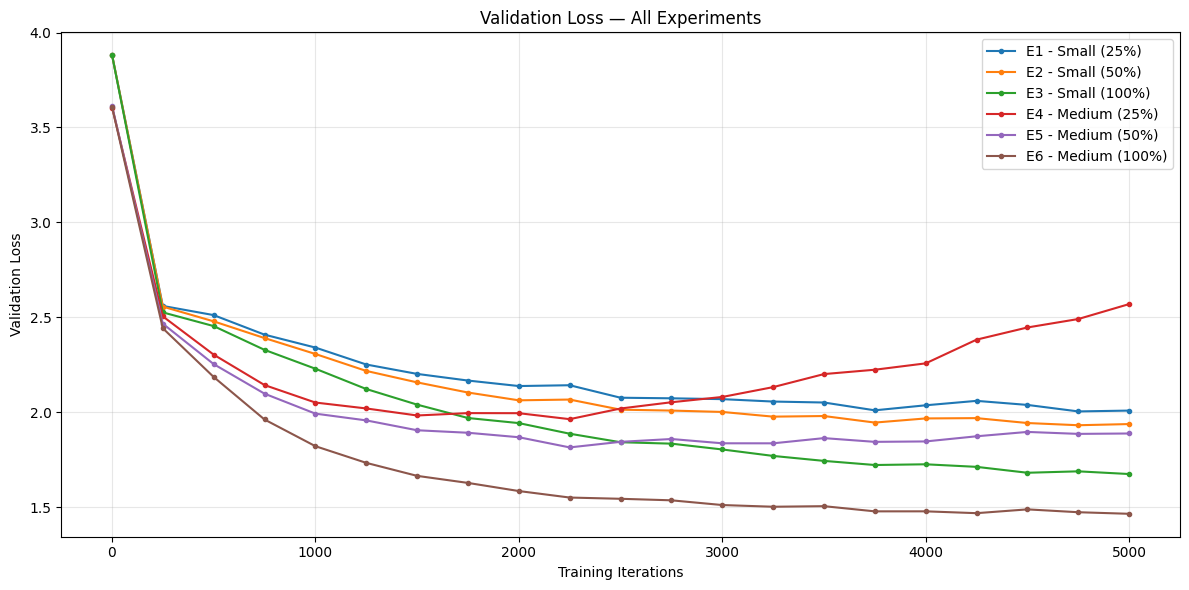

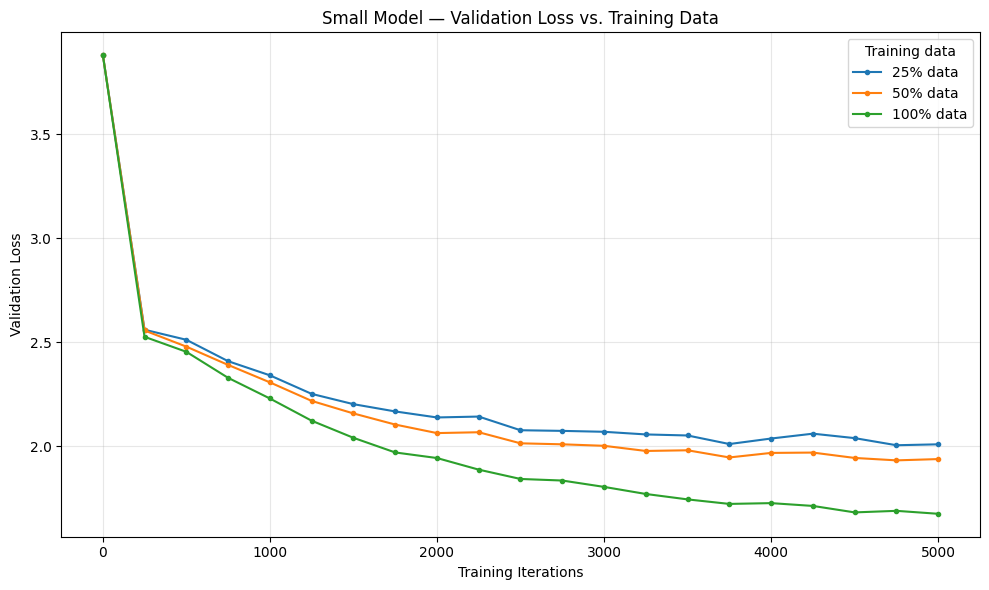

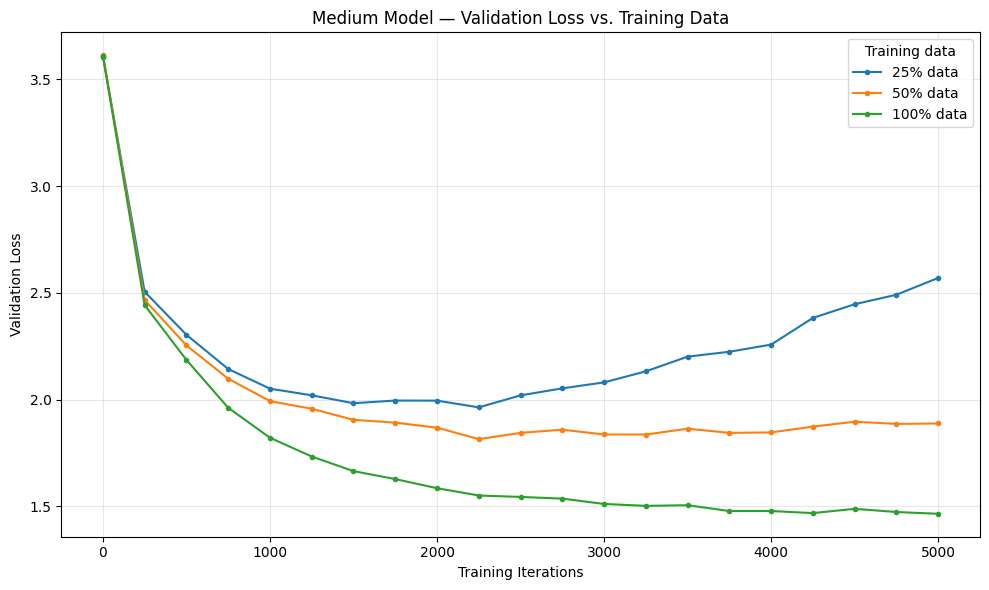


All plots saved successfully!
Location: /content/drive/MyDrive/nanoGPT-Scaling-Laws/results/plots

Files:
- training_loss_all.png
- validation_loss_all.png
- small_model_comparison.png
- medium_model_comparison.png
- scaling_data.png
- scaling_model.png


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/nanoGPT-Scaling-Laws"
RESULTS_DIR = os.path.join(BASE_DIR, "results")
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")

os.makedirs(PLOTS_DIR, exist_ok=True)

experiments = {
    "E1": ("Small", "25%"),
    "E2": ("Small", "50%"),
    "E3": ("Small", "100%"),
    "E4": ("Medium", "25%"),
    "E5": ("Medium", "50%"),
    "E6": ("Medium", "100%"),
}

# Load all metrics
metrics = {}

for exp in experiments:
    path = os.path.join(RESULTS_DIR, exp, "metrics.csv")
    metrics[exp] = pd.read_csv(path)

# --------------------------------------------------
# Plot 1: Training loss — all experiments
# --------------------------------------------------

plt.figure(figsize=(12, 6))

for exp, (model, data_pct) in experiments.items():
    df = metrics[exp]
    plt.plot(
        df["iteration"],
        df["train_loss"],
        marker="o",
        markersize=3,
        label=f"{exp} - {model} ({data_pct})"
    )

plt.title("Training Loss — All Experiments")
plt.xlabel("Training Iterations")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS_DIR, "training_loss_all.png"),
    dpi=300
)
plt.show()


# --------------------------------------------------
# Plot 2: Validation loss — all experiments
# --------------------------------------------------

plt.figure(figsize=(12, 6))

for exp, (model, data_pct) in experiments.items():
    df = metrics[exp]
    plt.plot(
        df["iteration"],
        df["val_loss"],
        marker="o",
        markersize=3,
        label=f"{exp} - {model} ({data_pct})"
    )

plt.title("Validation Loss — All Experiments")
plt.xlabel("Training Iterations")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS_DIR, "validation_loss_all.png"),
    dpi=300
)
plt.show()


# --------------------------------------------------
# Plot 3: Small model — dataset size comparison
# --------------------------------------------------

plt.figure(figsize=(10, 6))

for exp in ["E1", "E2", "E3"]:
    df = metrics[exp]
    data_pct = experiments[exp][1]

    plt.plot(
        df["iteration"],
        df["val_loss"],
        marker="o",
        markersize=3,
        label=f"{data_pct} data"
    )

plt.title("Small Model — Validation Loss vs. Training Data")
plt.xlabel("Training Iterations")
plt.ylabel("Validation Loss")
plt.legend(title="Training data")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS_DIR, "small_model_comparison.png"),
    dpi=300
)
plt.show()


# --------------------------------------------------
# Plot 4: Medium model — dataset size comparison
# --------------------------------------------------

plt.figure(figsize=(10, 6))

for exp in ["E4", "E5", "E6"]:
    df = metrics[exp]
    data_pct = experiments[exp][1]

    plt.plot(
        df["iteration"],
        df["val_loss"],
        marker="o",
        markersize=3,
        label=f"{data_pct} data"
    )

plt.title("Medium Model — Validation Loss vs. Training Data")
plt.xlabel("Training Iterations")
plt.ylabel("Validation Loss")
plt.legend(title="Training data")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS_DIR, "medium_model_comparison.png"),
    dpi=300
)
plt.show()


print("\nAll plots saved successfully!")
print("Location:", PLOTS_DIR)
print("\nFiles:")
for filename in os.listdir(PLOTS_DIR):
    print("-", filename)

## 4. Comparison table of the 6 experiments  *(task: compare the 6 experiments)*

In [ ]:
import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/nanoGPT-Scaling-Laws"
RESULTS_DIR = os.path.join(BASE_DIR, "results")

test_results = pd.read_csv(
    os.path.join(RESULTS_DIR, "test_evaluation.csv")
)

summary = []

experiment_info = {
    "E1": ("Small", "25%"),
    "E2": ("Small", "50%"),
    "E3": ("Small", "100%"),
    "E4": ("Medium", "25%"),
    "E5": ("Medium", "50%"),
    "E6": ("Medium", "100%"),
}

for exp, (model_type, data_pct) in experiment_info.items():

    metrics_path = os.path.join(
        RESULTS_DIR, exp, "metrics.csv"
    )

    df = pd.read_csv(metrics_path)

    best_idx = df["val_loss"].idxmin()
    best_row = df.loc[best_idx]
    final_row = df.iloc[-1]

    test_row = test_results[
        test_results["Experiment"] == exp
    ].iloc[0]

    summary.append({
        "Experiment": exp,
        "Model": model_type,
        "Training Data": data_pct,
        "Parameters": int(test_row["Parameters"]),
        "Training Iterations": int(final_row["iteration"]),
        "Best Iteration": int(best_row["iteration"]),
        "Final Train Loss": final_row["train_loss"],
        "Best Validation Loss": best_row["val_loss"],
        "Final Validation Loss": final_row["val_loss"],
        "Test Loss": test_row["Test Loss"],
        "Test Perplexity": test_row["Test Perplexity"],
        "Training Time (seconds)": final_row["elapsed_seconds"]
    })

summary_df = pd.DataFrame(summary)

output_path = os.path.join(
    RESULTS_DIR, "final_experiment_summary.csv"
)

summary_df.to_csv(output_path, index=False)

display(summary_df.round(4))

print("\nFinal summary saved to:")
print(output_path)

,Experiment,Model,Training Data,Parameters,Training Iterations,Best Iteration,Final Train Loss,Best Validation Loss,Final Validation Loss,Test Loss,Test Perplexity,Training Time (seconds)
0,E1,Small,25%,828672,5000,4750,1.3807,2.0041,2.0085,2.1067,8.2213,226.0463
1,E2,Small,50%,828672,5000,4750,1.4363,1.9314,1.9376,2.0416,7.7031,228.6050
2,E3,Small,100%,828672,5000,5000,1.5197,1.6743,1.6743,1.8887,6.6105,228.7472
3,E4,Medium,25%,4804096,5000,2250,0.4576,1.9634,2.5696,2.0911,8.0939,849.8522
4,E5,Medium,50%,4804096,5000,2250,0.9915,1.8146,1.8879,1.9612,7.1080,853.2988
5,E6,Medium,100%,4804096,5000,5000,1.1966,1.4648,1.4648,1.7430,5.7144,853.1593



Final summary saved to:
/content/drive/MyDrive/nanoGPT-Scaling-Laws/results/final_experiment_summary.csv


##Updating the comparison table with Bigram :

In [ ]:
import os
import pandas as pd
import numpy as np

# ------------------------------------------
# 1. Paths
# ------------------------------------------

BASE_DIR = "/content/drive/MyDrive/nanoGPT-Scaling-Laws"
RESULTS_DIR = os.path.join(BASE_DIR, "results")

# Dataset used by the Bigram baseline
REPO_DIR = "/content/nanoGPT-Scaling-Laws"
TRAIN_PATH = os.path.join(
    REPO_DIR, "data", "processed", "train_100.bin"
)
TEST_PATH = os.path.join(
    REPO_DIR, "data", "processed", "test.bin"
)

# Check files
assert os.path.exists(TRAIN_PATH), f"Training file not found: {TRAIN_PATH}"
assert os.path.exists(TEST_PATH), f"Test file not found: {TEST_PATH}"

# ------------------------------------------
# 2. Load test evaluation results
# ------------------------------------------

test_csv_path = os.path.join(
    RESULTS_DIR, "test_evaluation.csv"
)

assert os.path.exists(test_csv_path), (
    f"Test results file not found: {test_csv_path}"
)

test_results = pd.read_csv(test_csv_path)

required_columns = [
    "Experiment",
    "Parameters",
    "Test Loss",
    "Test Perplexity"
]

missing_columns = [
    col for col in required_columns
    if col not in test_results.columns
]

assert not missing_columns, (
    f"Missing columns in test_evaluation.csv: {missing_columns}"
)

summary = []

experiment_info = {
    "E1": ("Small", "25%"),
    "E2": ("Small", "50%"),
    "E3": ("Small", "100%"),
    "E4": ("Medium", "25%"),
    "E5": ("Medium", "50%"),
    "E6": ("Medium", "100%"),
}

# ------------------------------------------
# 3. Add the six Transformer experiments
# ------------------------------------------

for exp, (model_type, data_pct) in experiment_info.items():

    metrics_path = os.path.join(
        RESULTS_DIR, exp, "metrics.csv"
    )

    assert os.path.exists(metrics_path), (
        f"Metrics file not found for {exp}: {metrics_path}"
    )

    df = pd.read_csv(metrics_path)

    if df.empty:
        raise ValueError(f"metrics.csv is empty for {exp}")

    required_metrics = [
        "iteration",
        "train_loss",
        "val_loss",
        "elapsed_seconds"
    ]

    missing_metrics = [
        col for col in required_metrics
        if col not in df.columns
    ]

    assert not missing_metrics, (
        f"Missing columns in {exp}/metrics.csv: {missing_metrics}"
    )

    best_idx = df["val_loss"].idxmin()
    best_row = df.loc[best_idx]
    final_row = df.iloc[-1]

    matching_test = test_results[
        test_results["Experiment"] == exp
    ]

    if matching_test.empty:
        raise ValueError(
            f"No test evaluation result found for {exp}"
        )

    test_row = matching_test.iloc[0]

    summary.append({
        "Experiment": exp,
        "Model": model_type,
        "Training Data": data_pct,
        "Parameters": int(test_row["Parameters"]),
        "Training Iterations": int(final_row["iteration"]),
        "Best Iteration": int(best_row["iteration"]),
        "Final Train Loss": final_row["train_loss"],
        "Best Validation Loss": best_row["val_loss"],
        "Final Validation Loss": final_row["val_loss"],
        "Test Loss": test_row["Test Loss"],
        "Test Perplexity": test_row["Test Perplexity"],
        "Training Time (seconds)": final_row["elapsed_seconds"]
    })

# ------------------------------------------
# 4. Add Bigram baseline
# ------------------------------------------

bigram_rows = test_results[
    test_results["Experiment"] == "Bigram"
]

if bigram_rows.empty:
    raise ValueError(
        "Bigram results are missing from test_evaluation.csv. "
        "Run the Bigram evaluation cell first and save its results."
    )

bigram = bigram_rows.iloc[-1]

summary.append({
    "Experiment": "Bigram",
    "Model": "Baseline",
    "Training Data": "100%",
    "Parameters": int(bigram["Parameters"]),
    "Training Iterations": "N/A",
    "Best Iteration": "N/A",
    "Final Train Loss": np.nan,
    "Best Validation Loss": np.nan,
    "Final Validation Loss": np.nan,
    "Test Loss": bigram["Test Loss"],
    "Test Perplexity": bigram["Test Perplexity"],
    "Training Time (seconds)": "N/A"
})

# ------------------------------------------
# 5. Display and save final comparison
# ------------------------------------------

summary_df = pd.DataFrame(summary)

# Keep the experiments in the requested order
order = ["E1", "E2", "E3", "E4", "E5", "E6", "Bigram"]

summary_df["Experiment"] = pd.Categorical(
    summary_df["Experiment"],
    categories=order,
    ordered=True
)

summary_df = summary_df.sort_values(
    "Experiment"
).reset_index(drop=True)

# Save final comparison
output_path = os.path.join(
    RESULTS_DIR, "final_experiment_summary.csv"
)

summary_df.to_csv(output_path, index=False)

print("FINAL COMPARISON — 6 TRANSFORMERS + BIGRAM\n")

display(summary_df.round(4))

print("\nSaved to:", output_path)


FINAL COMPARISON — 6 TRANSFORMERS + BIGRAM



,Experiment,Model,Training Data,Parameters,Training Iterations,Best Iteration,Final Train Loss,Best Validation Loss,Final Validation Loss,Test Loss,Test Perplexity,Training Time (seconds)
0,E1,Small,25%,828672,5000,4750,1.3807,2.0041,2.0085,2.1067,8.2213,226.046252
1,E2,Small,50%,828672,5000,4750,1.4363,1.9314,1.9376,2.0416,7.7031,228.604986
2,E3,Small,100%,828672,5000,5000,1.5197,1.6743,1.6743,1.8887,6.6105,228.747213
3,E4,Medium,25%,4804096,5000,2250,0.4576,1.9634,2.5696,2.0911,8.0939,849.852247
4,E5,Medium,50%,4804096,5000,2250,0.9915,1.8146,1.8879,1.9612,7.1080,853.298834
5,E6,Medium,100%,4804096,5000,5000,1.1966,1.4648,1.4648,1.7430,5.7144,853.159318
6,Bigram,Baseline,100%,4225,N/A,N/A,NaN,NaN,NaN,2.5035,12.2248,N/A



Saved to: /content/drive/MyDrive/nanoGPT-Scaling-Laws/results/final_experiment_summary.csv


## 5. Generated samples  *(task: analyse the generated texts)*

Criteria from the README: dialogue structure, local coherence, repetition, character consistency, possible memorisation.

In [ ]:
import os
import torch
import pickle

from src.models.model import GPT, GPTConfig

# --------------------------------------------------
# 1. Load tokenizer
# --------------------------------------------------

with open("data/processed/meta.pkl", "rb") as f:
    meta = pickle.load(f)

stoi = meta["stoi"]
itos = meta["itos"]

# --------------------------------------------------
# 2. Generation settings
# --------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/nanoGPT-Scaling-Laws"
device = "cuda" if torch.cuda.is_available() else "cpu"

prompt = "ROMEO:"
max_new_tokens = 500
temperature = 0.8

selected_experiments = ["E1", "E3", "E4", "E6"]

# Encode prompt
prompt_ids = [stoi[ch] for ch in prompt]
context = torch.tensor(
    [prompt_ids],
    dtype=torch.long,
    device=device
)

# --------------------------------------------------
# 3. Generate text from each checkpoint
# --------------------------------------------------

generated_texts = {}

for exp in selected_experiments:

    checkpoint_path = os.path.join(
        BASE_DIR, "results", exp, "best.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    config = GPTConfig(**checkpoint["config"])
    model = GPT(config).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    # Reset seed for comparable sampling
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    with torch.no_grad():
        generated_ids = model.generate(
            context,
            max_new_tokens=max_new_tokens,
            temperature=temperature
        )

    # Decode generated tokens
    generated_chars = [
        itos[int(idx)] for idx in generated_ids[0].tolist()
    ]

    generated_text = "".join(generated_chars)
    generated_texts[exp] = generated_text

    print("\n" + "=" * 70)
    print(f"EXPERIMENT: {exp}")
    print("=" * 70)
    print(generated_text)

    del model, checkpoint
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# --------------------------------------------------
# 4. Save generated samples
# --------------------------------------------------

output_path = os.path.join(
    BASE_DIR, "results", "generated_samples.txt"
)

with open(output_path, "w", encoding="utf-8") as f:
    for exp, generated_text in generated_texts.items():
        f.write("=" * 70 + "\n")
        f.write(f"EXPERIMENT: {exp}\n")
        f.write("=" * 70 + "\n")
        f.write(generated_text + "\n\n")

print("\nGenerated samples saved to:")
print(output_path)


EXPERIMENT: E1
ROMEO:

Ou are noble present that do thank he beters.

First Murderer:
No, for the worst of the state,
What it is a city followed a more thy
brother say the resent greater: grant to the people
That upon the senators me, where thee?

First Murderer:
We have he would of thou worth hearts,
And his not of you to your blood,
When speak peace him the on one.

First Citizen:
Your not what tell mine of stabb'd's a denides
But the be so hare speak on my for your was to to your many are to-not
be such a with ha

EXPERIMENT: E3
ROMEO:
Fat that that done good a mode and all beters.

FLORIZEL:
You be lappersers we stroke me state.
What it is a ever thank man, your hast shall mean the
re hath we me make not shall here to-for upon it.

GLOUCESTER:
There thee storrow that let hands and a was so call;
Who shall must and his not and so thou tat lord,
When speak pentue to many so shell now my him death;
That what tender of all the dukes not for his speak:
The Duke of Marcius gracious as s

##             Generated Text Analysis :

###E1 — Small model, 25% data
- Format: The model correctly produces character names followed by colons. It recognizes the basic structure of a theatrical dialogue. It also separates speakers into different sections. The formatting resembles a Shakespeare play despite the poor language quality.

- Real words: Many words are recognizable English words, such as noble, present, thank, brother, state and city. However, some combinations are incorrect. The word beters appears malformed. The model has learned English vocabulary but does not always use it correctly.

- Repetition: Some common words and sentence constructions are reused. The model shows limited variation in its expressions. Repetition is noticeable in the short excerpt, although a full output is needed to measure it accurately.

- Coherence: 	Most sentences do not communicate a clear meaning. Words are placed together without proper grammatical relationships. The dialogue does not develop a logical conversation between characters. Overall, the text is difficult to understand.

- Memorisation: The presence of Shakespearean vocabulary does not prove memorisation. The excerpt contains no identified exact quotation. A comparison with the original Shakespeare corpus is necessary to determine whether any passage was copied.

Conclusion: E1 learns the basic theatrical format and some English vocabulary, but its grammar and coherence are weak.

###E3 — Small model, 100% data
- Format : Character names such as ROMEO and FLORIZEL are correctly formatted. The model maintains the structure of a theatrical dialogue. It successfully reproduces the expected speaker-label pattern

- Real words : 	The sample contains recognizable words such as good, done, state, thank, man and mean. Some generated words, such as lappersers, are malformed or not standard English. The model demonstrates a broader vocabulary but still makes lexical errors.

- Repetition : Repeated constructions such as that that and frequent use of short common words are visible. Some phrases appear repetitive. However, the output also contains different character names and expressions.

- Coherence : 	The text contains more recognizable sentence structures, but most sentences remain grammatically incorrect. Individual words can be understood, while their combinations often lack meaning. The dialogue is not consistently logical.

- Memorisation : 	The sample uses vocabulary and character names associated with Shakespearean theatre. However, this is not sufficient evidence of memorisation. No exact copied Shakespeare passage has been identified from the available excerpt.

Conclusion: E3 benefits from the complete training dataset. It demonstrates more varied vocabulary and theatrical patterns, but its generated sentences remain largely incoherent.

###E4 — Medium model, 25% data
- Format : 	The model correctly generates uppercase character names followed by colons. It produces multiple speakers and separates their dialogue. The theatrical structure is recognizable and correctly maintained.

- Real Words : 	Several recognizable English words appear, including first, servant, distress, pray, pity, content and made. However, Secomes and paperise appear malformed in this context. The model knows some appropriate vocabulary but combines it incorrectly.

- Repition : Common words and sentence structures are reused. Some constructions lack variation. Nevertheless, the text contains different expressions and speaker names. The complete sample is needed to determine the extent of repetition.

- Coherence : Some phrases resemble meaningful English sentences, but the overall dialogue is difficult to understand. Incorrect word combinations and grammatical structures affect readability. The conversation does not develop a consistent meaning.

- Memorisation : Shakespeare-like character names and vocabulary are present. However, no exact copied line can be confirmed from this excerpt. Original-corpus comparison is required to identify memorised passages.

Conclusion: E4 demonstrates that a larger model can learn recognizable theatrical structures, even with limited data. However, increasing model size alone does not guarantee coherent language generation.

###E6 — Medium model, 100% data
- Format : The model consistently generates character names followed by colons. It includes several speakers, such as ROMEO, Clown, PAULINA and ESCALUS. The output strongly resembles the format of a theatrical script.

- Real Wordds : Most visible words are recognizable English words, including mother, lord, unhappy, king, common, part, pardon and story. The vocabulary is more varied and readable than in E1. However, some expressions remain grammatically incorrect.

- Repition : The model still repeats short expressions. For example, Go, sir, be sir contains repeated use of sir. However, the sample includes more varied vocabulary and sentence structures than E1.

- Coherence : 	Some individual phrases are understandable, but the overall dialogue remains fragmented. Certain lines have recognizable meaning, while others contain incorrect grammatical constructions. The conversation does not maintain a consistent narrative between characters.

- Memorisation : 	The model generates Shakespeare-like vocabulary and character names. However, the presence of these elements does not establish memorisation. Exact textual overlap must be checked against the original corpus before making a conclusion.

Conclusion: E6 produces the strongest qualitative sample among the four experiments. It has more recognizable English vocabulary and better local sentence structure, although its dialogue is still not consistently coherent.

### Final report conclusion :

The generated texts from E1, E3, E4 and E6 were evaluated using five criteria: format, real English words, repetition, coherence and memorisation.

First, all four models successfully reproduced the basic theatrical format. They generated uppercase character names followed by colons, demonstrating that they learned the structural patterns of Shakespearean plays.

Regarding vocabulary, all models produced recognizable English words, but the quality differed. E1 contained more malformed words and incorrect word combinations, while E6 demonstrated more varied and recognizable vocabulary.

Repetition was observed in all four experiments. Some words and expressions appeared repeatedly, particularly in E1 and E3. E6 also showed repetition, although its vocabulary and sentence structures were more varied.

Concerning coherence, the generated texts remained grammatically imperfect. E1 produced mostly incoherent sentences, while E3 and E4 showed some recognizable sentence structures. E6 provided the strongest qualitative result, with several locally understandable expressions. Nevertheless, none of the models consistently generated a logical conversation.

Finally, memorisation cannot be established from the generated samples alone. Although the models reproduced Shakespearean vocabulary and character names, exact copying must be verified by comparing their outputs with the original training corpus.

Overall, E6 produced the best qualitative result among the four experiments, while E1 produced the weakest. The results suggest that increasing model size and training data can improve vocabulary and local readability. However, these improvements do not guarantee grammatically correct or fully coherent dialogue.

##  Scaling-law graphs :

Medium: test_loss ~ data^(-0.131)
Small: test_loss ~ data^(-0.079)


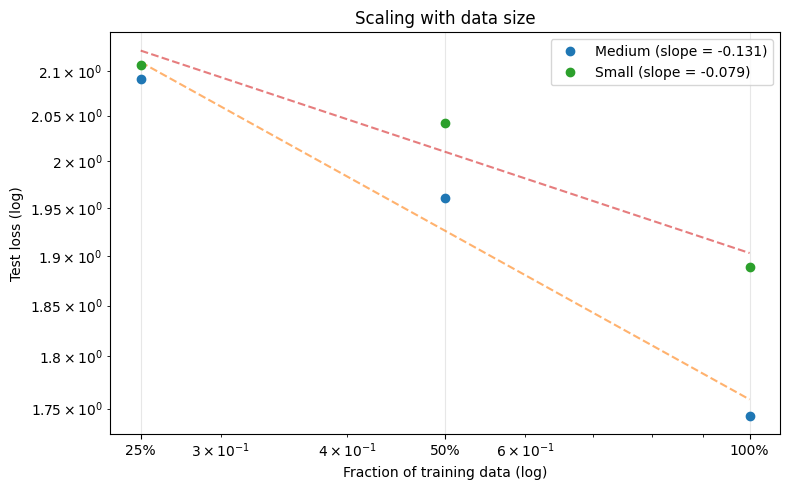

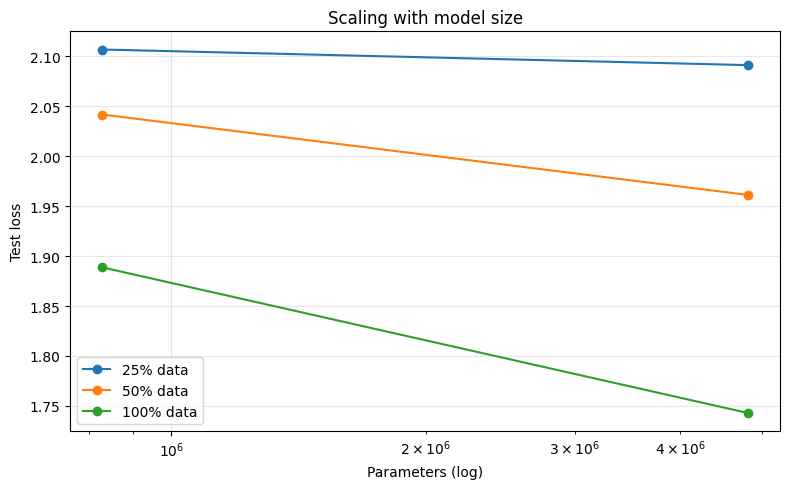

In [ ]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/content/drive/MyDrive/nanoGPT-Scaling-Laws/results"
df = pd.read_csv(os.path.join(RESULTS_DIR, "test_evaluation.csv"))
df["Data fraction"] = df["Data"].str.rstrip("%").astype(float) / 100

plt.figure(figsize=(8, 5))
for model, group in df.groupby("Model"):
    x, y = group["Data fraction"].values, group["Test Loss"].values
    slope, intercept = np.polyfit(np.log(x), np.log(y), 1)
    plt.plot(x, y, "o", label=f"{model} (slope = {slope:.3f})")
    xs = np.linspace(x.min(), x.max(), 50)
    plt.plot(xs, np.exp(intercept) * xs**slope, "--", alpha=0.6)
    print(f"{model}: test_loss ~ data^({slope:.3f})")

plt.xscale("log"); plt.yscale("log")
plt.xlabel("Fraction of training data (log)")
plt.ylabel("Test loss (log)")
plt.title("Scaling with data size")
plt.xticks([0.25, 0.5, 1.0], ["25%", "50%", "100%"])
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "plots", "scaling_data.png"), dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
for frac, group in df.groupby("Data fraction"):
    group = group.sort_values("Parameters")
    plt.plot(group["Parameters"], group["Test Loss"], "o-", label=f"{int(frac*100)}% data")
plt.xscale("log")
plt.xlabel("Parameters (log)"); plt.ylabel("Test loss")
plt.title("Scaling with model size")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "plots", "scaling_model.png"), dpi=300)
plt.show()

### Analysis Report

The scaling-law experiments investigate how the quantity of training data and the size of the Transformer model influence nanoGPT performance. Test Loss is used as the main evaluation metric, with lower values indicating better predictive performance.

**1. Scaling with Training Data Size**

The first experiment studies the relationship between training dataset size and Test Loss using log-log plots and power-law fitting.

For the Small model, the estimated scaling exponent is approximately -0.079, while for the Medium model it is approximately -0.131.

Both exponents are negative, indicating that Test Loss decreases as the quantity of training data increases. The Medium model exhibits a steeper negative slope, suggesting that it benefits more from additional training data than the Small model.

These observations demonstrate a positive relationship between training data quantity and model performance.

**2. Scaling with Model Size**

The second experiment examines the effect of increasing the number of model parameters.

The Small model contains 828,672 parameters, whereas the Medium model contains 4,804,096 parameters, approximately 5.8 times more.

The Medium model achieves lower Test Loss at every training-data percentage:

- At 25% data, Test Loss decreases from 2.1067 to 2.0911.
- At 50% data, Test Loss decreases from 2.0416 to 1.9612.
- At 100% data, Test Loss decreases from 1.8887 to 1.7430.

The improvement becomes more significant as the quantity of training data increases. This suggests that a larger model can make better use of additional training data and achieve better predictive performance.

**3. Overall Interpretation**

The two scaling experiments demonstrate that both model capacity and training dataset size influence nanoGPT performance.

Increasing the amount of training data consistently reduces Test Loss for both architectures. Similarly, increasing model size improves performance at all three dataset percentages.

The power-law fitting provides an empirical description of how Test Loss changes with training data quantity. However, the estimated exponents are based on only three data points per model.

The model-size comparison is also limited to two architectures, which is insufficient to establish a general power-law relationship between parameter count and performance.

**Conclusion**

The experimental results support the hypothesis that larger models and larger training datasets can improve Transformer performance. They also suggest that model capacity and data quantity work together: the Medium model demonstrates a greater performance improvement when trained with more data.

Nevertheless, these experiments represent limited empirical evidence rather than a universal scaling law. Further experiments using additional model sizes and training-data quantities would be necessary to establish more reliable scaling relationships.